<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_1_Tratamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caso 1 — OsteoRed: fractura durante el seguimiento

Trabajamos con una cohorte simulada de pacientes de OsteoRed.

Cada fila representa una paciente. La variable `ever` indica si
se observó una fractura durante su seguimiento:

- `ever = 1`: se observó una fractura.
- `ever = 0`: terminó su observación sin una fractura registrada.

Nuestro primer objetivo es conocer la estructura de los datos
y calcular qué proporción de pacientes presentó una fractura.

In [1]:
url_cohorte <- paste0(
    "https://raw.githubusercontent.com/JulTob/Modelling/main/",
    "GLM/Datos/Osteored/cohorte.rds"
    )

download.file(
    url_cohorte,
    destfile = "cohorte.rds",
    mode = "wb"
    )

cohorte <- readRDS("cohorte.rds")

In [2]:
dim(cohorte)
    #--> n pacientes · m variables.
head(cohorte)

[1] 803   9

,id,centro,x1,x2,tiempo,evento,ever,clase_nom,sever_ord
,<int>,<fct>,<dbl>,<int>,<int>,<int>,<int>,<fct>,<ord>
1,1,1,0.0605002,0,3,0,0,C,Leve
2,2,1,0.6324950,1,6,0,0,C,Moderado
3,3,1,-0.7137340,1,6,0,0,A,Moderado
4,4,1,-0.7710438,1,6,0,0,C,Leve
5,5,1,0.5808291,1,5,0,0,B,Moderado
6,6,1,0.2369371,1,5,0,0,A,Leve


- `id` — identifica a la paciente.
- `centro` — identifica su clínica.
- `x1` — fragilidad ósea, expresada como una variable continua estandarizada.
- `x2` — tratamiento preventivo: 0 si no lo recibe y 1 si lo recibe.
- `ever` — indica si se observó una fractura durante su seguimiento.

In [3]:
table(
    cohorte$ever,
    useNA = "ifany") # valores ausentes visibles

mean(cohorte$ever)


  0   1 
556 247 

[1] 0.3075965

En esta cohorte, se observó una fractura durante el seguimiento de `247` de las `803` pacientes, aproximadamente el `30,76 %`.

# Puntos Clave:
- Cada fila en `cohorte`representa una paciente a lo largo del estudio.
- `Ever` es un valor binario (booleano) indicando la presencia (positiva:=1) de fractura, o su ausencia (negativa:=0).
- `mean(ever)` es la proporción observada de fractura a lo largo del estudio. Este valor por sí mismo no identifica factores con relación en el estudio.  

----

# $\color{skyblue}✙$  ¿Cómo se distribuye la fragilidad ósea entre las pacientes con y sin fractura observada, dentro de cada grupo de tratamiento?



In [4]:
# Instalar ggplot2
if (!requireNamespace("ggplot2", quietly = TRUE)) {
    install.packages(
        "ggplot2",
        repos = "https://cloud.r-project.org"
        )
    }

library(ggplot2)

# Preparar etiquetas para el gráfico.
datos_grafico <- transform(
    cohorte,

    fractura = factor(
        ever,
        levels = c(0, 1),
        labels = c("No", "Sí")
        ),

    tratamiento = factor(
        x2,
        levels = c(0, 1),
        labels = c("Sin tratamiento", "Con tratamiento")
        )
    )


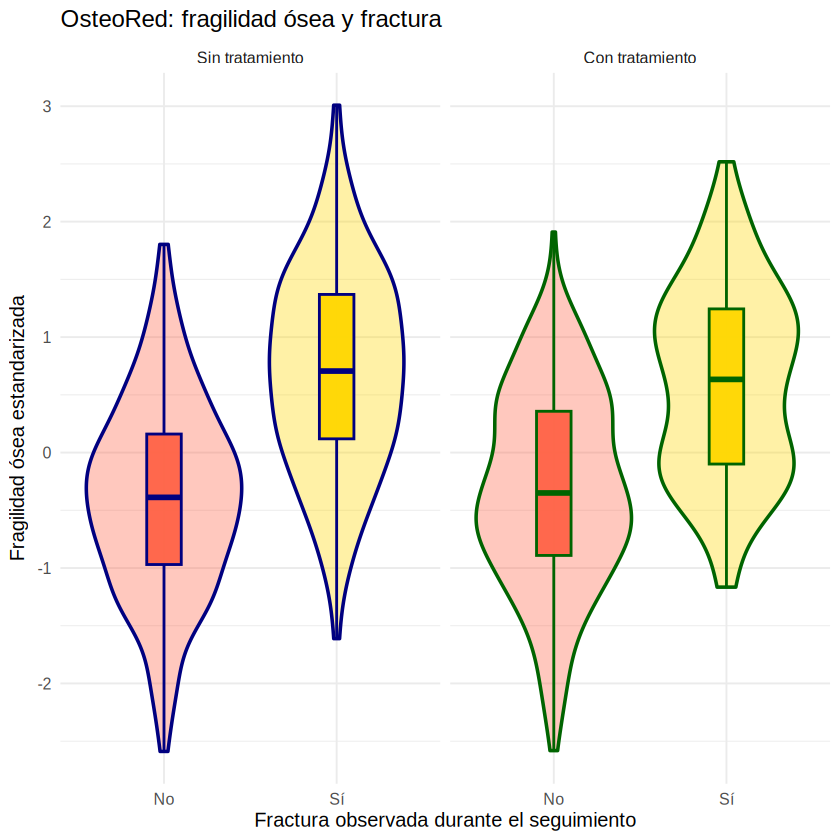

In [5]:
ggplot(
    datos_grafico,
    aes(
        x = fractura,
        y = x1,
        fill = fractura,
        colour = tratamiento
        )
    ) + geom_violin(
        alpha = 0.35,
        linewidth = 1.0
    ) + geom_boxplot(
        width = 0.2,
        alpha = 0.95,
        linewidth = 0.8,
        outlier.alpha = 0.4,
        outlier.size = 1.2
    ) + facet_wrap(
        ~ tratamiento
    ) + scale_fill_manual(
        values = c(
            "No" = "Tomato",
            "Sí" = "Gold"
            )
    ) + scale_colour_manual(
        values = c(
            "Sin tratamiento" = "Navy",
            "Con tratamiento" = "DarkGreen"
            )
    ) + labs(
        title = "OsteoRed: fragilidad ósea y fractura",
        x = "Fractura observada durante el seguimiento",
        y = "Fragilidad ósea estandarizada"
    ) + guides(
        fill = "none",
        colour = "none"
    ) + theme_minimal(
        base_size = 12)


### Observaciones:
- Fragilidad, más alta en pacientes con factura. Los rangos tienen solapamiento, con areas de clara diferenciación.
- Poca diferencia visual entre Con/Sin Tratamiento.


-----